本 notebook 是 [M02.8 随机过程与采样](../notes/08-stochastic-processes-sampling.qmd) 的实例讲解。

1. 1. Markov 链与平稳分布
2. 2. Metropolis–Hastings 与拒绝步骤
3. 3. 二维 Langevin 与步长偏差
4. 4. 自相关、有效样本量与重要性采样

在 VS Code 中选择仓库 `.venv` 内核，逐单元运行；运行结果随文件保存。示例使用固定随机种子和合成数据。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy.stats import norm

from semiai.plotting import BLUE, ORANGE, use_style

use_style()
set_matplotlib_formats("svg")
rng = np.random.default_rng(42)

## 1. Markov 链与平稳分布

平稳分布是转移算子的固定点；用一个两状态可逆链直接检查，再从不同初态迭代观察靠近。

In [2]:
P = np.array([[0.9, 0.1], [0.3, 0.7]])
pi = np.array([0.75, 0.25])
print("平稳残差:", pi @ P - pi)
print("详细平衡两侧:", pi[0] * P[0, 1], pi[1] * P[1, 0])
for initial in (np.array([1.0, 0.0]), np.array([0.0, 1.0])):
    print("20 步后的分布:", initial @ np.linalg.matrix_power(P, 20))
assert np.allclose(pi @ P, pi)

平稳残差: [0. 0.]
详细平衡两侧: 0.07500000000000001 0.075
20 步后的分布: [0.75000914 0.24999086]
20 步后的分布: [0.74997258 0.25002742]


读法：平稳不等于从任意初态立即达到平衡；不可约、非周期等条件决定离散链是否能从一般初态收敛。详细平衡是平稳的充分条件而非必要条件。

## 2. Metropolis–Hastings 与拒绝步骤

在一维双势阱上使用对称高斯提议。拒绝后必须保留原状态，不能只记录接受的位置。

In [3]:
T = 0.6
x = 1.0
chain = []
accepted = 0
for _ in range(45000):
    proposal = x + rng.normal(scale=0.7)
    logratio = -((proposal**2 - 1) ** 2 - (x * x - 1) ** 2) / T
    if np.log(rng.random()) < min(0.0, logratio):
        x = proposal
        accepted += 1
    chain.append(x)
chain = np.array(chain[5000:])
grid = np.linspace(-2.5, 2.5, 1000)
density = np.exp(-((grid * grid - 1) ** 2) / T)
density /= np.trapezoid(density, grid)
reference = np.trapezoid(grid * grid * density, grid)
print("接受率:", accepted / 45000, "正井占据比例:", np.mean(chain > 0))
print("二阶矩（采样/参考）:", np.mean(chain**2), reference)
assert abs(np.mean(chain**2) - reference) < 0.08

接受率: 0.5573111111111111 正井占据比例: 0.50495
二阶矩（采样/参考）: 0.850875472343349 0.8402478907790839


读法：拒绝带来的停留时间属于目标分布的一部分。接受率高也可能意味着提议太小、混合很慢；需要同时检查跨井和相关性。

## 3. 二维 Langevin 与步长偏差

对 U(x,y)=(x²−1)²+y²/2 进行过阻尼采样，比较两个解析边缘分布。

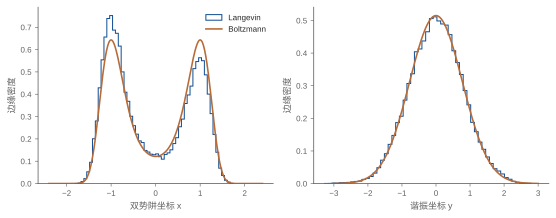

x 均值 / x²（采样/参考）: -0.11898072691940546 0.8481379215445279 0.840247890779084
y 方差（采样/参考）: 0.6202749805397084 0.6
Euler OU 离散稳态方差，h=.4、T=.6: 0.7499999999999999


In [4]:
T = 0.6
h = 0.005
state = rng.normal(size=(16, 2))
stored = []
for step in range(18000):
    grad = np.column_stack([4 * state[:, 0] * (state[:, 0] ** 2 - 1), state[:, 1]])
    state = state - h * grad + np.sqrt(2 * T * h) * rng.normal(size=state.shape)
    if step >= 3000 and step % 5 == 0:
        stored.append(state.copy())
samples = np.stack(stored).reshape(-1, 2)
xgrid = np.linspace(-2.4, 2.4, 400)
px = np.exp(-((xgrid * xgrid - 1) ** 2) / T)
px /= np.trapezoid(px, xgrid)
ygrid = np.linspace(-3, 3, 400)
fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.1))
axes[0].hist(samples[:, 0], bins=55, density=True, histtype="step", color=BLUE, label="Langevin")
axes[0].plot(xgrid, px, color=ORANGE, label="Boltzmann")
axes[0].set(xlabel="双势阱坐标 x", ylabel="边缘密度")
axes[0].legend()
axes[1].hist(samples[:, 1], bins=55, density=True, histtype="step", color=BLUE)
axes[1].plot(ygrid, norm.pdf(ygrid, scale=np.sqrt(T)), color=ORANGE)
axes[1].set(xlabel="谐振坐标 y", ylabel="边缘密度")
fig.tight_layout()
plt.show()

reference_x2 = np.trapezoid(xgrid * xgrid * px, xgrid)
print("x 均值 / x²（采样/参考）:", samples[:, 0].mean(), np.mean(samples[:, 0] ** 2), reference_x2)
print("y 方差（采样/参考）:", samples[:, 1].var(), T)
print("Euler OU 离散稳态方差，h=.4、T=.6:", 0.6 / (1 - 0.4 / 2))
assert np.isfinite(samples).all()
assert abs(np.mean(samples[:, 0] ** 2) - reference_x2) < 0.08

读法：有限步长的 Euler–Maruyama 通常存在平衡分布偏差；对线性 OU 过程甚至可解析写出该偏差。减小步长与延长采样解决的是不同误差。

## 4. 自相关、有效样本量与重要性采样

比较相关链的名义样本数与近似有效样本量，再用移位高斯更频繁地访问稀有尾部。

In [5]:
centered = chain - chain.mean()
acf = np.array(
    [np.dot(centered[:-lag], centered[lag:]) / np.dot(centered, centered) for lag in range(1, 151)]
)
positive = []
for value in acf:
    if value <= 0:
        break
    positive.append(value)
ess = len(chain) / (1 + 2 * np.sum(positive))
print("名义样本数:", len(chain), "基于首次非正截断的近似 ESS:", ess)
n = 60000
plain = rng.normal(size=n)
shifted = rng.normal(3, 1, size=n)
weighted = (shifted > 3) * np.exp(norm.logpdf(shifted) - norm.logpdf(shifted, loc=3))
print("P(X>3)（解析/普通 MC/重要性）:", norm.sf(3), np.mean(plain > 3), weighted.mean())
print(
    "估计标准误（普通/重要性）:",
    np.std(plain > 3, ddof=1) / np.sqrt(n),
    weighted.std(ddof=1) / np.sqrt(n),
)

名义样本数: 40000 基于首次非正截断的近似 ESS: 2194.9992311023766
P(X>3)（解析/普通 MC/重要性）: 0.001349898031630093 0.0014166666666666668 0.0013357263212875595
估计标准误（普通/重要性）: 0.0001535514734693889 1.0049888864661304e-05


读法：有效样本量依赖所估计的观测量与截断规则；这里是诊断示例。重要性采样用似然比纠正提议分布，支持集覆盖和权重尾部决定它是否可靠。

## 小结

平稳分布是转移规则的固定点，混合决定有限时间能否接近它。Metropolis 校正与 Langevin 梯度漂移提供两种构造路径；Fokker–Planck 连接路径与密度。相关性、离散步长和权重方差分别控制不同误差，诊断时不能混为一谈。